<a href="https://colab.research.google.com/github/salnagisa0120/dl-uts-kelompok-17/blob/main/kode/Task_2_Time_series_Regresion_Remaining_Useful_Life.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installasi Library

In [1]:
!pip -q install numpy pandas matplotlib scikit-learn torch

import dataset

In [2]:
import os
import zipfile

# Ganti nama file sesuai dengan nama file zip Anda jika berbeda
zip_file_name = "clustering.zip"

if os.path.exists(zip_file_name):
    print(f"Mengekstrak {zip_file_name}...")
    with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
        zip_ref.extractall("/content")
    print("Ekstraksi selesai!")
else:
    # Mencari file zip apa saja yang ada di folder jika nama di atas tidak cocok
    all_zips = [f for f in os.listdir('.') if f.endswith('.zip')]
    if all_zips:
        chosen_zip = all_zips[0]
        print(f"Menemukan berkas zip: {chosen_zip}. Mengekstrak...")
        with zipfile.ZipFile(chosen_zip, 'r') as zip_ref:
            zip_ref.extractall("/content")
        print("Ekstraksi selesai!")
    else:
        print("Gagal: Tidak ditemukan berkas .zip di folder /content. Silakan unggah berkas .zip Anda terlebih dahulu.")

# Verifikasi file setelah ekstraksi
required_files = {"clustering.npz", "clustering_meta.csv"}
missing = {f for f in required_files if not os.path.exists(f)}
if not missing:
    print("Semua dataset yang diperlukan ditemukan dan siap digunakan!")
else:
    print(f"Peringatan: Berkas berikut masih belum ditemukan: {missing}")

Menemukan berkas zip: data_uts_dl.zip. Mengekstrak...
Ekstraksi selesai!
Semua dataset yang diperlukan ditemukan dan siap digunakan!


Import Library dan konfigurasi

In [3]:
import os, random, copy, json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
WINDOW = 30
WINDOW_STRIDE = 3
BATCH_SIZE = 256
EPOCHS = 20
PATIENCE = 4
MC_PASSES = 40
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print("Device:", DEVICE)

Device: cpu


load data dan eksplorasi

In [4]:
train_raw = pd.read_csv("/content/rul_train.csv.gz")
test_raw = pd.read_csv("/content/rul_test.csv.gz")

print("Train:", train_raw.shape, "| mesin:", train_raw.id_unit.nunique())
print("Test :", test_raw.shape,  "| mesin:", test_raw.id_unit.nunique())
display(train_raw.head())
display(train_raw.isna().mean().sort_values(ascending=False).head(10).rename("missing_fraction").to_frame())

sensor_cols = [f"s{i:02d}" for i in range(1, 22)]
setting_cols = ["setel_1", "setel_2", "setel_3"]
feature_cols = setting_cols + sensor_cols
assert set(["id_unit", "siklus"] + feature_cols).issubset(train_raw.columns)

Train: (254174, 26) | mesin: 900
Test : (51692, 26) | mesin: 300


,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,3,1,20.001,0.7005,100.0,1107.746,569.289,991.700,1099.533,NaN,...,1092.248,1144.779,1345.634,873.087,851.099,408.142,997.673,838.331,1012.076,439.003
1,3,2,34.996,0.8424,100.0,1071.040,587.821,1013.673,NaN,157.684,...,1095.511,1167.320,1340.661,871.230,791.396,398.338,980.601,814.985,1108.741,412.368
2,3,3,0.001,-0.0012,100.0,1130.132,585.094,998.221,1127.436,161.918,...,1091.245,1170.340,1330.785,872.114,807.389,388.304,938.802,847.512,1003.616,455.443
3,3,4,35.001,0.8375,100.0,1080.962,585.775,1016.998,1152.147,NaN,...,1096.911,1173.207,1348.423,877.459,784.038,399.505,978.649,813.737,1113.184,411.554
4,3,5,9.998,0.2483,100.0,1095.013,580.506,997.108,1119.245,169.359,...,1102.956,1159.881,1341.195,872.265,772.284,NaN,950.568,821.425,969.681,362.551


,missing_fraction
s20,0.021131
s02,0.020742
s06,0.020596
s18,0.020596
s07,0.020533
s04,0.020517
s12,0.020431
s09,0.020352
s13,0.020309
s19,0.020285


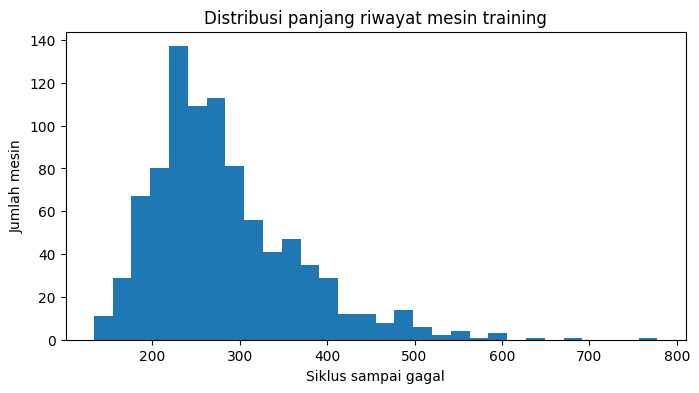

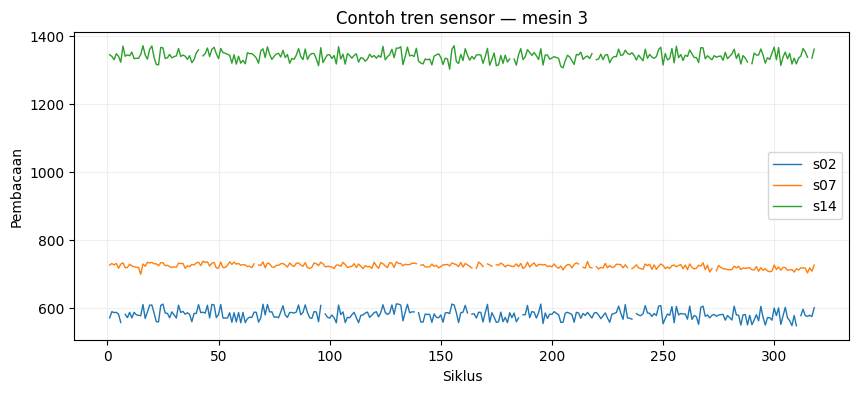

In [5]:
# Panjang riwayat tiap mesin
life = train_raw.groupby("id_unit")["siklus"].max()
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(life, bins=30)
ax.set(title="Distribusi panjang riwayat mesin training", xlabel="Siklus sampai gagal", ylabel="Jumlah mesin")
plt.show()

# Contoh perubahan beberapa sensor pada satu mesin
sample_id = train_raw.id_unit.iloc[0]
sample = train_raw[train_raw.id_unit == sample_id].sort_values("siklus")
fig, ax = plt.subplots(figsize=(10,4))
for col in ["s02", "s07", "s14"]:
    ax.plot(sample.siklus, sample[col], label=col, linewidth=1)
ax.set(title=f"Contoh tren sensor — mesin {sample_id}", xlabel="Siklus", ylabel="Pembacaan")
ax.legend(); ax.grid(alpha=.2); plt.show()

Label RUL

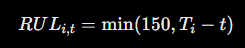

In [6]:
# Buat label RUL dari riwayat run-to-failure
train_labeled = train_raw.copy()
failure_cycle = train_labeled.groupby("id_unit")["siklus"].transform("max")
train_labeled["RUL"] = (failure_cycle - train_labeled["siklus"]).clip(lower=0, upper=150).astype(np.float32)

# Split group: 80% mesin untuk training, 20% mesin untuk validation
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, va_idx = next(gss.split(train_labeled, groups=train_labeled["id_unit"]))
train_part = train_labeled.iloc[tr_idx].copy()
val_part = train_labeled.iloc[va_idx].copy()

train_units = set(train_part.id_unit.unique())
val_units = set(val_part.id_unit.unique())
assert train_units.isdisjoint(val_units)

# Simulasikan titik prediksi sebelum failure untuk setiap mesin validation.
# RUL target tetap dihitung terhadap siklus failure asli pada val_part.
rng = np.random.default_rng(SEED)
cut_rows = []
for uid, grp in val_part.groupby("id_unit"):
    grp = grp.sort_values("siklus")
    life_end = int(grp["siklus"].max())
    cutoff_target = int(rng.uniform(0.55, 0.85) * life_end)
    eligible = grp[grp["siklus"] <= cutoff_target]
    if eligible.empty:
        eligible = grp.iloc[[0]]
    cutoff_cycle = int(eligible["siklus"].max())
    cut_rows.append(grp[grp["siklus"] <= cutoff_cycle])
val_cutoff_part = pd.concat(cut_rows).sort_values(["id_unit", "siklus"]).copy()

print("Mesin train:", len(train_units), "| mesin validation:", len(val_units))
print("Baris validation yang disimulasikan:", len(val_cutoff_part))
print("RUL target validation:", val_cutoff_part.groupby("id_unit").tail(1)["RUL"].describe())

Mesin train: 720 | mesin validation: 180
Baris validation yang disimulasikan: 34883
RUL target validation: count    180.000000
mean      83.866669
std       34.095234
min       25.000000
25%       58.750000
50%       76.500000
75%      106.750000
max      150.000000
Name: RUL, dtype: float64


Pre-processing untuk sensor

In [7]:
# Statistik preprocessing hanya dari training split
raw_train_features = train_part[feature_cols].replace([np.inf, -np.inf], np.nan)
medians = raw_train_features.median()
q_low = raw_train_features.quantile(0.01)
q_high = raw_train_features.quantile(0.99)

def clean_frame(frame):
    x = frame[feature_cols].replace([np.inf, -np.inf], np.nan)
    x = x.fillna(medians)
    x = x.clip(lower=q_low, upper=q_high, axis="columns")
    return x

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# Imputer/scaler fit pada training split saja
Xtr_raw = clean_frame(train_part)
Xva_raw = clean_frame(val_cutoff_part)
Xte_raw = clean_frame(test_raw)

Xtr = scaler.fit_transform(imputer.fit_transform(Xtr_raw)).astype(np.float32)
Xva = scaler.transform(imputer.transform(Xva_raw)).astype(np.float32)
Xte = scaler.transform(imputer.transform(Xte_raw)).astype(np.float32)

print("Fitur:", Xtr.shape[1], "| NaN setelah preprocessing:", np.isnan(Xtr).sum())

Fitur: 24 | NaN setelah preprocessing: 0


Sliding Windows

In [8]:
def make_windows(frame, X, window=WINDOW, stride=WINDOW_STRIDE, with_labels=True, last_only=False):
    # frame dan X harus memiliki urutan baris yang sama
    seqs, ys, groups, ends = [], [], [], []
    positions = {idx: pos for pos, idx in enumerate(frame.index)}
    for uid, grp in frame.groupby("id_unit", sort=False):
        grp = grp.sort_values("siklus")
        pos = np.array([positions[i] for i in grp.index], dtype=int)
        arr = X[pos]
        end_positions = [len(arr)-1] if last_only else list(range(0, len(arr), stride))
        if not last_only and end_positions[-1] != len(arr)-1:
            end_positions.append(len(arr)-1)
        for e in end_positions:
            start = max(0, e-window+1)
            w = arr[start:e+1]
            if len(w) < window:
                pad = np.repeat(w[:1], window-len(w), axis=0)
                w = np.concatenate([pad, w], axis=0)
            seqs.append(w)
            groups.append(uid)
            ends.append(int(grp.iloc[e]["siklus"]))
            if with_labels:
                ys.append(float(grp.iloc[e]["RUL"]))
    Xseq = np.asarray(seqs, dtype=np.float32)
    if with_labels:
        return Xseq, np.asarray(ys, dtype=np.float32), np.asarray(groups), np.asarray(ends)
    return Xseq, np.asarray(groups), np.asarray(ends)

X_train_seq, y_train, g_train, cyc_train = make_windows(train_part, Xtr, with_labels=True)
X_val_seq, y_val, g_val, cyc_val = make_windows(val_cutoff_part, Xva, with_labels=True, last_only=True)

print("Train windows:", X_train_seq.shape, "| Validation last-cycle:", X_val_seq.shape)

Train windows: (68639, 30, 24) | Validation last-cycle: (180, 30, 24)


Baseline untuk non-deep learning

In [9]:
def summarize_windows(X):
    last = X[:, -1, :]
    mean = X.mean(axis=1)
    std = X.std(axis=1)
    return np.concatenate([last, mean, std], axis=1)

X_train_base = summarize_windows(X_train_seq)
X_val_base = summarize_windows(X_val_seq)

baseline = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
baseline.fit(X_train_base, y_train)
pred_base = np.clip(baseline.predict(X_val_base), 0, 150)

model sequence: LSTM dan 1D-CNN

In [10]:
class SeqDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        if self.y is None: return self.X[i]
        return self.X[i], self.y[i]

class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=96, dropout=0.25):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=2, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(1)

class CNN1DRegressor(nn.Module):
    def __init__(self, n_features, dropout=0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_features, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 96, 5, padding=2), nn.BatchNorm1d(96), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(96, 128, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(128, 64), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x.transpose(1, 2))

def train_model(model, Xtr, ytr, Xva, yva, epochs=EPOCHS):
    train_loader = DataLoader(SeqDataset(Xtr, ytr), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(SeqDataset(Xva, yva), batch_size=BATCH_SIZE, shuffle=False)
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.HuberLoss(delta=10.0)
    best_loss, best_state, patience = float("inf"), None, 0
    history = {"train": [], "val": []}
    for epoch in range(epochs):
        model.train(); tr_losses=[]
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tr_losses.append(loss.item())
        model.eval(); va_losses=[]
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                va_losses.append(loss_fn(model(xb), yb).item())
        tr, va = float(np.mean(tr_losses)), float(np.mean(va_losses))
        history["train"].append(tr); history["val"].append(va)
        print(f"Epoch {epoch+1:02d}: train={tr:.3f}, val={va:.3f}")
        if va < best_loss:
            best_loss, best_state, patience = va, copy.deepcopy(model.state_dict()), 0
        else:
            patience += 1
            if patience >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, history

lstm_model, lstm_history = train_model(
    LSTMRegressor(X_train_seq.shape[2]), X_train_seq, y_train, X_val_seq, y_val)
cnn_model, cnn_history = train_model(
    CNN1DRegressor(X_train_seq.shape[2]), X_train_seq, y_train, X_val_seq, y_val)

Epoch 01: train=635.721, val=433.300
Epoch 02: train=214.611, val=270.665
Epoch 03: train=138.663, val=223.089
Epoch 04: train=133.774, val=208.669
Epoch 05: train=131.626, val=186.773
Epoch 06: train=129.610, val=207.320
Epoch 07: train=129.181, val=208.609
Epoch 08: train=127.525, val=193.254
Epoch 09: train=126.617, val=201.721


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:1150: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.huber_loss(input, target, reduction=self.reduction, delta=self.delta)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:1150: UserWarning: Using a target size (torch.Size([31])) that is different to the input size (torch.Size([31, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.huber_loss(input, target, reduction=self.reduction, delta=self.delta)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:1150: UserWarning: Using a target size (torch.Size([180])) that is different to the input size (torch.Size([180, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they

Epoch 01: train=461.626, val=389.501
Epoch 02: train=377.660, val=456.085
Epoch 03: train=377.309, val=424.177
Epoch 04: train=377.221, val=476.203
Epoch 05: train=376.802, val=404.032


Evaluasi RMSE dan asymetric score

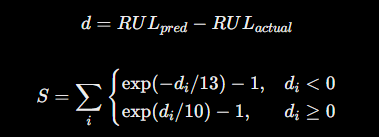

In [11]:
def asymmetric_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    terms = np.where(d < 0, np.exp(np.clip(-d/13, -50, 50)) - 1,
                     np.exp(np.clip(d/10, -50, 50)) - 1)
    return float(np.sum(terms))

def metrics_row(name, y_true, y_pred):
    y_pred = np.clip(np.asarray(y_pred), 0, 150)
    return {
        "model": name,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "Asymmetric_Score": asymmetric_score(y_true, y_pred)
    }

def predict_model(model, X):
    model.eval()
    loader = DataLoader(SeqDataset(X), batch_size=BATCH_SIZE, shuffle=False)
    out=[]
    with torch.no_grad():
        for xb in loader:
            out.append(model(xb.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

pred_lstm = np.clip(predict_model(lstm_model, X_val_seq), 0, 150)
pred_cnn = np.clip(predict_model(cnn_model, X_val_seq), 0, 150)

results = pd.DataFrame([
    metrics_row("Ridge baseline", y_val, pred_base),
    metrics_row("LSTM", y_val, pred_lstm),
    metrics_row("1D-CNN", y_val, pred_cnn)
])
display(results.sort_values("RMSE"))

,model,RMSE,MAE,Asymmetric_Score
1,LSTM,29.531480,23.228786,8.917723e+03
0,Ridge baseline,36.541651,30.841553,2.575988e+04
2,1D-CNN,50.330053,43.766369,2.693611e+07


In [12]:
# RMSE per rentang RUL
def rmse_by_range(y_true, y_pred):
    ranges = [(0,30), (30,60), (60,100), (100,151)]
    rows=[]
    for lo, hi in ranges:
        mask = (y_true >= lo) & (y_true < hi)
        if mask.sum():
            rows.append({"RUL_range": f"{lo}-{hi-1}", "n": int(mask.sum()),
                         "RMSE": float(np.sqrt(mean_squared_error(y_true[mask], y_pred[mask])))})
    return pd.DataFrame(rows)

display(rmse_by_range(y_val, pred_lstm))

,RUL_range,n,RMSE
0,0-29,1,0.005806
1,30-59,45,23.605830
2,60-99,83,29.659139
3,100-150,51,33.981467


Visualisasai validasi prediksi

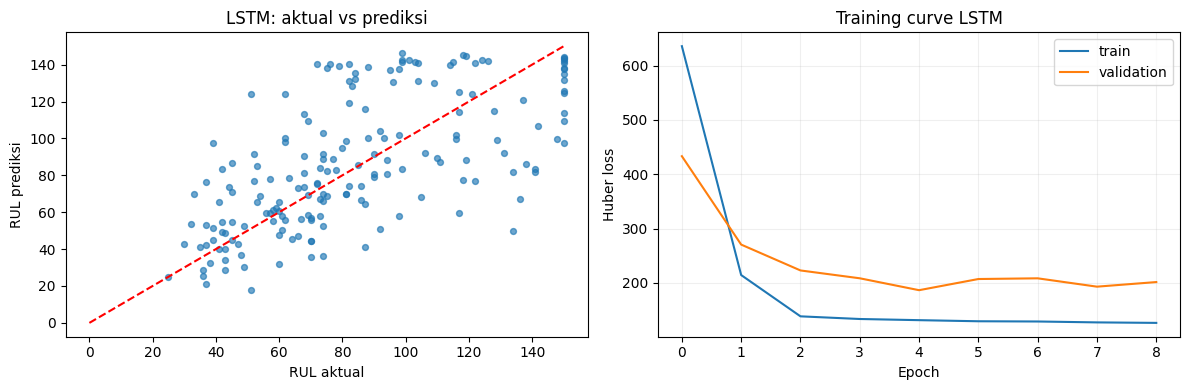

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].scatter(y_val, pred_lstm, alpha=.65, s=18)
axes[0].plot([0,150],[0,150],"r--")
axes[0].set(xlabel="RUL aktual", ylabel="RUL prediksi", title="LSTM: aktual vs prediksi")
axes[1].plot(lstm_history["train"], label="train")
axes[1].plot(lstm_history["val"], label="validation")
axes[1].set(title="Training curve LSTM", xlabel="Epoch", ylabel="Huber loss")
axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

Uncertainly dengan Monte Carlo Dropout

In [14]:
def mc_dropout_predict(model, X, passes=MC_PASSES):
    model.train()  # aktifkan dropout saat inferensi
    loader = DataLoader(SeqDataset(X), batch_size=BATCH_SIZE, shuffle=False)
    draws=[]
    for _ in range(passes):
        pred=[]
        with torch.no_grad():
            for xb in loader:
                pred.append(model(xb.to(DEVICE)).cpu().numpy())
        draws.append(np.concatenate(pred))
    model.eval()
    draws = np.stack(draws, axis=0)
    mean = np.clip(draws.mean(axis=0), 0, 150)
    low = np.clip(np.percentile(draws, 5, axis=0), 0, 150)
    high = np.clip(np.percentile(draws, 95, axis=0), 0, 150)
    return mean, low, high, draws

val_mean, val_low, val_high, val_draws = mc_dropout_predict(lstm_model, X_val_seq)

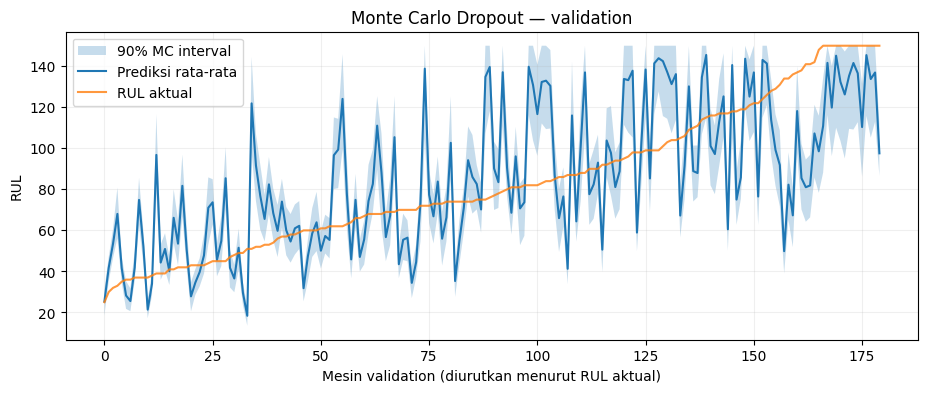

Empirical coverage interval 90%: 0.411


In [15]:
# Contoh interval prediksi pada validation
order = np.argsort(y_val)
plt.figure(figsize=(11,4))
xpos = np.arange(len(order))
plt.fill_between(xpos, val_low[order], val_high[order], alpha=.25, label="90% MC interval")
plt.plot(xpos, val_mean[order], label="Prediksi rata-rata")
plt.plot(xpos, y_val[order], label="RUL aktual", alpha=.8)
plt.xlabel("Mesin validation (diurutkan menurut RUL aktual)")
plt.ylabel("RUL")
plt.title("Monte Carlo Dropout — validation")
plt.legend(); plt.grid(alpha=.2); plt.show()

coverage = np.mean((y_val >= val_low) & (y_val <= val_high))
print(f"Empirical coverage interval 90%: {coverage:.3f}")

Prediksi RUL pada dataset

In [16]:
X_test_seq, test_groups, test_ends = make_windows(
    test_raw, Xte, with_labels=False, last_only=True)

test_mean, test_low, test_high, test_draws = mc_dropout_predict(
    lstm_model, X_test_seq, passes=MC_PASSES)

predictions = pd.DataFrame({
    "id_unit": test_groups,
    "siklus_terakhir": test_ends,
    "RUL_prediksi": test_mean,
    "RUL_interval_5%": test_low,
    "RUL_interval_95%": test_high
})

# Aturan operasional contoh: prioritaskan servis jika batas atas interval sudah rendah.
# Ambang ini harus disesuaikan dengan biaya downtime, risiko keselamatan, dan kebijakan pabrik.
def service_advice(row):
    if row["RUL_interval_95%"] <= 20:
        return "Prioritaskan inspeksi/servis segera"
    if row["RUL_interval_5%"] <= 20:
        return "Jadwalkan inspeksi lebih awal; ketidakpastian tinggi"
    if row["RUL_prediksi"] <= 40:
        return "Rencanakan servis dalam waktu dekat"
    return "Lanjutkan operasi dan pantau"

predictions["rekomendasi"] = predictions.apply(service_advice, axis=1)
display(predictions.head(10))
predictions.to_csv("/content/rul_test_predictions.csv", index=False)
print("Jumlah prediksi:", len(predictions), "| harus sama dengan jumlah mesin test:", test_raw.id_unit.nunique())

,id_unit,siklus_terakhir,RUL_prediksi,RUL_interval_5%,RUL_interval_95%,rekomendasi
0,1,119,62.509022,47.878834,72.859520,Lanjutkan operasi dan pantau
1,2,436,19.475412,13.942078,27.182993,Jadwalkan inspeksi lebih awal; ketidakpastian ...
2,6,156,91.364342,78.231140,106.370232,Lanjutkan operasi dan pantau
3,8,107,144.305328,118.001236,150.000000,Lanjutkan operasi dan pantau
4,16,170,33.722042,26.873232,40.622986,Rencanakan servis dalam waktu dekat
5,21,160,33.564747,27.846510,39.793411,Rencanakan servis dalam waktu dekat
6,23,73,147.597000,126.458488,150.000000,Lanjutkan operasi dan pantau
7,28,84,143.052155,119.160667,150.000000,Lanjutkan operasi dan pantau
8,30,175,143.332535,119.011528,150.000000,Lanjutkan operasi dan pantau
9,34,70,139.674347,111.330513,150.000000,Lanjutkan operasi dan pantau


Jumlah prediksi: 300 | harus sama dengan jumlah mesin test: 300


Simpan dan download

In [17]:
import shutil
from google.colab import files

# Simpan metrik validasi dan prediksi test
results.to_csv("/content/validation_metrics.csv", index=False)
rmse_by_range(y_val, pred_lstm).to_csv("/content/validation_rmse_by_rul_range.csv", index=False)

with open("/content/experiment_summary.json", "w") as f:
    json.dump({
        "validation_machines": int(len(val_units)),
        "test_machines": int(len(predictions)),
        "window": WINDOW,
        "window_stride": WINDOW_STRIDE,
        "best_model_candidate": "LSTM (MC Dropout used for uncertainty)",
        "validation_metrics": results.to_dict(orient="records"),
        "test_note": "Test RUL labels are not supplied; test metrics cannot be computed."
    }, f, indent=2)

# Kumpulkan seluruh output penting ke dalam satu arsip
import zipfile
with zipfile.ZipFile("/content/rul_task2_results.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in [
        "rul_test_predictions.csv",
        "validation_metrics.csv",
        "validation_rmse_by_rul_range.csv",
        "experiment_summary.json"
    ]:
        fpath = Path("/content") / fname
        if fpath.exists():
            zf.write(fpath, arcname=fname)

files.download("/content/rul_task2_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>